# 06 — Model Comparison (baseline settings)
Both models are evaluated on the **same 2,000 held-out test records** and compared against the
majority-class baseline.

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable when running from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "electrical_grid_stability.csv"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
%matplotlib inline

In [2]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve
from src.preprocessing import load_and_split_data
from src.train_models import get_logistic_regression_pipeline, get_random_forest_model
from src.evaluation import evaluate_predictions

X_train, X_test, y_train, y_test = load_and_split_data(DATA_PATH)
models = {"Logistic Regression": get_logistic_regression_pipeline().fit(X_train, y_train),
          "Random Forest": get_random_forest_model().fit(X_train, y_train)}
results = {name: evaluate_predictions(y_test, m.predict(X_test)) for name, m in models.items()}
baseline = evaluate_predictions(y_test, np.full(len(y_test), "unstable"))

keys = ["accuracy", "macro_f1", "weighted_f1", "stable_precision", "stable_recall", "stable_f1",
        "unstable_precision", "unstable_recall", "unstable_f1"]
table = pd.DataFrame({"Majority baseline": {k: baseline[k] for k in keys},
                      **{n: {k: r[k] for k in keys} for n, r in results.items()}})
for name, r in {"Majority baseline": baseline, **results}.items():
    cm = r["confusion_matrix"]
    table.loc["false_stable (missed unstable)", name] = cm[1, 0]
    table.loc["false_unstable (false alarm)", name] = cm[0, 1]
table.round(4)

,Majority baseline,Logistic Regression,Random Forest
accuracy,0.6380,0.8200,0.9290
macro_f1,0.3895,0.8009,0.9220
weighted_f1,0.4970,0.8179,0.9285
stable_precision,0.0000,0.7774,0.9292
stable_recall,0.0000,0.7044,0.8702
stable_f1,0.0000,0.7391,0.8987
unstable_precision,0.6380,0.8408,0.9289
unstable_recall,1.0000,0.8856,0.9624
unstable_f1,0.7790,0.8626,0.9453
false_stable (missed unstable),0.0000,146.0000,48.0000


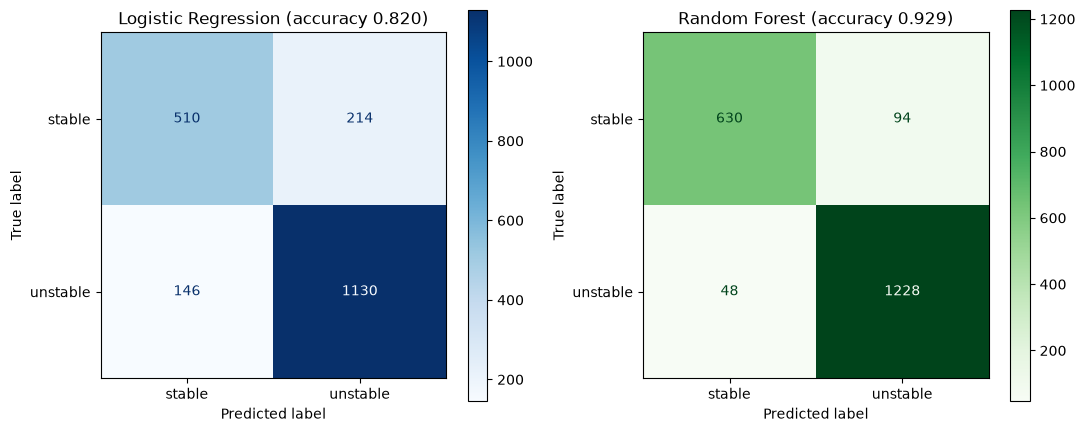

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, r), cmap in zip(axes, results.items(), ["Blues", "Greens"]):
    ConfusionMatrixDisplay(r["confusion_matrix"], display_labels=["stable", "unstable"]).plot(ax=ax, cmap=cmap, values_format="d")
    ax.set_title(f"{name} (accuracy {r['accuracy']:.3f})")
plt.tight_layout(); plt.show()

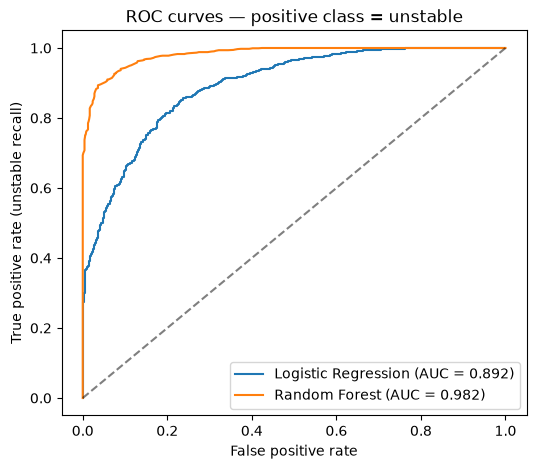

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, m in models.items():
    p = m.predict_proba(X_test)[:, list(m.classes_).index("unstable")]
    fpr, tpr, _ = roc_curve(y_test == "unstable", p)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test == 'unstable', p):.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (unstable recall)")
ax.set_title("ROC curves — positive class = unstable"); ax.legend(); plt.show()

**Interpretation:**
- Both models beat the 63.8% baseline. Random Forest is better on **every** metric: accuracy 92.9% vs
  82.0%, macro-F1 0.922 vs 0.801, and ROC-AUC ≈ 0.98 vs ≈ 0.89.
- The most safety-relevant error is a **false stable** (an unstable grid predicted stable), which
  would leave an instability unhandled. Random Forest makes 48 such errors versus 146 for
  Logistic Regression — about one-third as many.
- **False unstable** errors (false alarms) cost unnecessary control actions; Random Forest also makes
  fewer of these (94 vs 214).
- Stable recall is the weaker side for both models (LR 70%, RF 87%): the minority class is harder.
- The gap suggests the decision boundary is non-linear. Notebook 07 tests whether this is a limit of
  Logistic Regression itself or only of its *linear features*.